# Example 9.3 — Post-Optimization Analysis

**Chapter 9: Step-by-Step Trajectory Synthesis**

Evaluates the optimal mechanism: checks Grashof, calculates the transmission angle profile and compares it with the desired trajectory.

## 1. Parameters of the optimal mechanism

In [1]:
from numpy import *

r1 = 82.41
r2 = 38.67
r3 = 103.21
r4 = 91.08

xp_opt = 28.93
yp_opt = -12.47
theta20 = 14.32

print('Optimal mechanism found by the GA:')
print(f'  r1={r1} mm,  r2={r2} mm')
print(f'  r3={r3} mm,  r4={r4} mm')
print(f'  Coupler: xp={xp_opt} mm, yp={yp_opt} mm')
print(f'  Initial angle θ₂₀={theta20}°')

Optimal mechanism found by the GA:
  r1=82.41 mm,  r2=38.67 mm
  r3=103.21 mm,  r4=91.08 mm
  Coupler: xp=28.93 mm, yp=-12.47 mm
  Initial angle θ₂₀=14.32°


## 2. Grashof Verification

In [2]:
from numpy import *

longs = array([r1, r2, r3, r4])
s = min(longs)
l = max(longs)

resto = sorted(longs)[1:3]
p = resto[0]
q = resto[1]

grashof = (s + l) < (p + q)

print('=== Grashof Condition ===')
print(f'  s (minimum) = {s:.2f} mm')
print(f'  l (maximum) = {l:.2f} mm')
print(f'  p = {p:.2f} mm,  q = {q:.2f} mm')
print(f'  s+l = {s+l:.2f} mm,  p+q = {p+q:.2f} mm')
print(f'  Grashof: {"SATISFIED" if grashof else "NOT SATISFIED"}')

=== Grashof Condition ===
  s (minimum) = 38.67 mm
  l (maximum) = 103.21 mm
  p = 82.41 mm,  q = 91.08 mm
  s+l = 141.88 mm,  p+q = 173.49 mm
  Grashof: SATISFIED


## 3. Analysis of Transmission Angle

In [3]:
from numpy import *

def analizar(r1, r2, r3, r4, t2):
    A = 2 * r4 * (r1 - r2 * cos(t2))
    B = -2 * r2 * r4 * sin(t2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(t2)
    d = A**2 + B**2 - C**2

    if d < 0:
        return None, None

    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2(
        (r4 * sin(t4) - r2 * sin(t2)) / r3,
        (r1 + r4 * cos(t4) - r2 * cos(t2)) / r3
    )
    return t3, t4

t2_arr = linspace(radians(theta20), radians(theta20) + 2 * pi, 360)
mu_arr = []
ok = 0

for t2 in t2_arr:
    t3, t4 = analizar(r1, r2, r3, r4, t2)
    if t3 is not None:
        mu = degrees(abs(t3 - t4)) % 180
        if mu > 90:
            mu = 180 - mu
        mu_arr.append(mu)
        if 40 <= mu <= 140:
            ok += 1

mu_arr = array(mu_arr)
pct = 100.0 * ok / 360

print('=== Transmission Angle ===')
print(f'  Minimum μ:   {min(mu_arr):.2f}°')
print(f'  Maximum μ:   {max(mu_arr):.2f}°')
print(f'  Average μ:   {mean(mu_arr):.2f}°')
print(f'  % in optimal zone [40°,140°]: {pct:.1f}%')

=== Transmission Angle ===
  Minimum μ:   17.35°
  Maximum μ:   89.85°
  Average μ:   50.74°
  % in optimal zone [40°,140°]: 55.8%


## 4. Comparison of Desired vs. Obtained Trajectory

In [4]:
from numpy import *

N_PUNTOS = 20
t = linspace(0, 2 * pi, N_PUNTOS, endpoint=False)
fac = 1 - 0.5 * sin(t / 2)
xd = 100 + 50 * cos(t) * fac
yd = 100 + 50 * sin(t) * fac

t2_pts = linspace(radians(theta20), radians(theta20) + 2 * pi, N_PUNTOS, endpoint=False)
xa_arr = []
ya_arr = []
err_arr = []

for i, t2 in enumerate(t2_pts):
    t3, t4 = analizar(r1, r2, r3, r4, t2)
    if t3 is not None:
        xa = r2 * cos(t2) + xp_opt * cos(t3) - yp_opt * sin(t3)
        ya = r2 * sin(t2) + xp_opt * sin(t3) + yp_opt * cos(t3)
        xa_arr.append(xa)
        ya_arr.append(ya)
        err_arr.append(sqrt((xa - xd[i])**2 + (ya - yd[i])**2))

print(f'Mean error:  {mean(err_arr):.4f} mm')
print(f'Max error: {max(err_arr):.4f} mm')

Mean error:  115.7916 mm
Max error: 127.4034 mm


## 5. Visualizing Post-Optimization Analysis

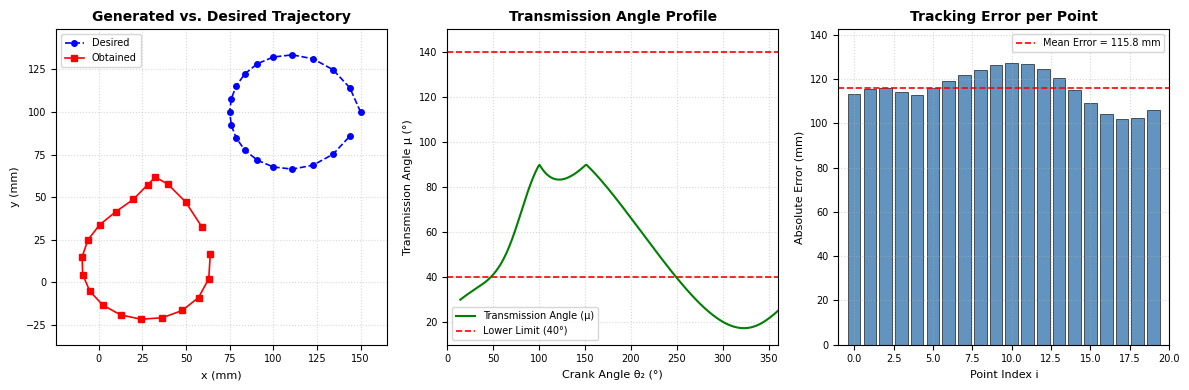

In [8]:
import matplotlib.pyplot as plt
from numpy import *
import os
import glob
import builtins

# 1. Automated file naming system according to publisher rules
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_9_3_post_optimization_analysis"
except Exception:
    notebook_name = "Figure_9_3_post_optimization_analysis"

# 2. Springer Publishing Quality Configurations
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']

# Font size guidelines for Springer (Title ~9-11pt, Labels/Legend ~7-9pt)
TITLE_SIZE = 10
LABEL_SIZE = 8
LEGEND_SIZE = 7
TICK_SIZE = 7

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Convert list to array to use numpy functions safely
xa_np = array(xa_arr)
ya_np = array(ya_arr)

# --- Subplot 1: Trajectories ---
axes[0].plot(xd, yd, 'b--o', ms=4, lw=1.2, label='Desired')
axes[0].plot(xa_np, ya_np, 'r-s', ms=4, lw=1.2, label='Obtained')
axes[0].set_title('Generated vs. Desired Trajectory', fontsize=TITLE_SIZE, fontweight='bold')
axes[0].legend(fontsize=LEGEND_SIZE, loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.5)
axes[0].set_xlabel('x (mm)', fontsize=LABEL_SIZE)
axes[0].set_ylabel('y (mm)', fontsize=LABEL_SIZE)
axes[0].tick_params(labelsize=TICK_SIZE)

# Safe numpy min/max calculation using builtins to prevent NumPy override conflict
x_min_val = builtins.min(builtins.float(amin(xd)), builtins.float(amin(xa_np))) - 15
x_max_val = builtins.max(builtins.float(amax(xd)), builtins.float(amax(xa_np))) + 15
y_min_val = builtins.min(builtins.float(amin(yd)), builtins.float(amin(ya_np))) - 15
y_max_val = builtins.max(builtins.float(amax(yd)), builtins.float(amax(ya_np))) + 15

axes[0].set_xlim(x_min_val, x_max_val)
axes[0].set_ylim(y_min_val, y_max_val)

# --- Subplot 2: Transmission Angle ---
t2d = degrees(t2_arr)
axes[1].plot(t2d[:len(mu_arr)], mu_arr, 'g-', lw=1.5, label='Transmission Angle (μ)')
axes[1].axhline(40, color='r', ls='--', lw=1.2, label='Lower Limit (40°)')
axes[1].axhline(140, color='r', ls='--', lw=1.2)
axes[1].set_title('Transmission Angle Profile', fontsize=TITLE_SIZE, fontweight='bold')
axes[1].legend(fontsize=LEGEND_SIZE, loc='lower left')
axes[1].grid(True, linestyle=':', alpha=0.5)
axes[1].set_xlabel('Crank Angle θ₂ (°)', fontsize=LABEL_SIZE)
axes[1].set_ylabel('Transmission Angle μ (°)', fontsize=LABEL_SIZE)
axes[1].tick_params(labelsize=TICK_SIZE)
# Configure limits with safety margins
axes[1].set_xlim(0, 360)
axes[1].set_ylim(10, 150)

# --- Subplot 3: Error per Point ---
err_np = array(err_arr)
axes[2].bar(range(len(err_np)), err_np, color='steelblue', alpha=0.85, edgecolor='black', linewidth=0.5)
axes[2].axhline(mean(err_np), color='r', ls='--', lw=1.2, label=f'Mean Error = {mean(err_np):.1f} mm')
axes[2].set_title('Tracking Error per Point', fontsize=TITLE_SIZE, fontweight='bold')
axes[2].legend(fontsize=LEGEND_SIZE, loc='upper right')
axes[2].grid(True, linestyle=':', alpha=0.5)
axes[2].set_xlabel('Point Index i', fontsize=LABEL_SIZE)
axes[2].set_ylabel('Absolute Error (mm)', fontsize=LABEL_SIZE)
axes[2].tick_params(labelsize=TICK_SIZE)
axes[2].set_xlim(-1, len(err_np))
axes[2].set_ylim(0, amax(err_np) + 15)

plt.tight_layout()

# 5. Dual Format Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()